## 8 Analysis Questions

**Univariate Analysis**
1. Which product category has the highest number of transactions?
2. Which product type is sold the most?
3. What is the most common transaction quantity?

**Bivariate Analysis**

4. How do transaction quantities vary across product categories?

5. Is there a relationship between unit price and transaction quantity?

**Group Comparison**

6. Which store location has the highest total sales?

7. Which month has the highest total sales?
8. Which product category generates the highest revenue?

In [4]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [5]:
# Read the Excel dataset
df = pd.read_excel('/content/Coffee Shop Sales.xlsx')

# Display the first 5 rows
df.head()

,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


In [6]:
# Show rows and columns
print(df.shape)

# Show column names
print(df.columns)

# Show data types and information
df.info()

(149116, 11)
Index(['transaction_id', 'transaction_date', 'transaction_time',
       'transaction_qty', 'store_id', 'store_location', 'product_id',
       'unit_price', 'product_category', 'product_type', 'product_detail'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   transaction_id    149116 non-null  int64         
 1   transaction_date  149116 non-null  datetime64[ns]
 2   transaction_time  149116 non-null  object        
 3   transaction_qty   149116 non-null  int64         
 4   store_id          149116 non-null  int64         
 5   store_location    149116 non-null  object        
 6   product_id        149116 non-null  int64         
 7   unit_price        149116 non-null  float64       
 8   product_category  149116 non-null  object        
 9   product_type      149116 non-null

In [7]:
# Show information about numerical columns
df.describe()

,transaction_id,transaction_date,transaction_qty,store_id,product_id,unit_price
count,149116.000000,149116,149116.000000,149116.000000,149116.000000,149116.000000
mean,74737.371872,2023-04-15 11:50:32.173609984,1.438276,5.342063,47.918607,3.382219
min,1.000000,2023-01-01 00:00:00,1.000000,3.000000,1.000000,0.800000
25%,37335.750000,2023-03-06 00:00:00,1.000000,3.000000,33.000000,2.500000
50%,74727.500000,2023-04-24 00:00:00,1.000000,5.000000,47.000000,3.000000
75%,112094.250000,2023-05-30 00:00:00,2.000000,8.000000,60.000000,3.750000
max,149456.000000,2023-06-30 00:00:00,8.000000,8.000000,87.000000,45.000000
std,43153.600016,NaN,0.542509,2.074241,17.930020,2.658723


In [8]:
# Show all column names
df.columns

Index(['transaction_id', 'transaction_date', 'transaction_time',
       'transaction_qty', 'store_id', 'store_location', 'product_id',
       'unit_price', 'product_category', 'product_type', 'product_detail'],
      dtype='object')

In [9]:
# Count missing values in each column
df.isnull().sum()

,0
transaction_id,0
transaction_date,0
transaction_time,0
transaction_qty,0
store_id,0
store_location,0
product_id,0
unit_price,0
product_category,0
product_type,0


In [10]:
# Count duplicate rows
df.duplicated().sum()

np.int64(0)

In [11]:
# Check data types of all columns
df.dtypes

,0
transaction_id,int64
transaction_date,datetime64[ns]
transaction_time,object
transaction_qty,int64
store_id,int64
store_location,object
product_id,int64
unit_price,float64
product_category,object
product_type,object


#Univariate Analysis

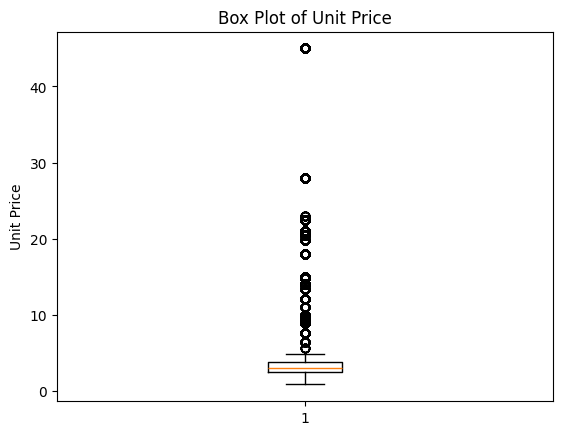

In [12]:
# Create a box plot for unit price

plt.boxplot(df['unit_price'])
plt.title('Box Plot of Unit Price')
plt.ylabel('Unit Price')
plt.show()

In [13]:
# Find Q1 and Q3
Q1 = df['unit_price'].quantile(0.25)
Q3 = df['unit_price'].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Find lower and upper limits
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Count outliers
outliers = df[(df['unit_price'] < lower) | (df['unit_price'] > upper)]

print("Lower limit:", lower)
print("Upper limit:", upper)
print("Number of outliers:", len(outliers))

Lower limit: 0.625
Upper limit: 5.625
Number of outliers: 4212


**"The unit_price column contains 4,212 outliers. These values are kept because they may represent genuine higher-priced products."**

In [14]:
# Find Q1 and Q3
Q1 = df['transaction_qty'].quantile(0.25)
Q3 = df['transaction_qty'].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Find lower and upper limits
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Count outliers
outliers = df[(df['transaction_qty'] < lower) | (df['transaction_qty'] > upper)]

print("Lower limit:", lower)
print("Upper limit:", upper)
print("Number of outliers:", len(outliers))

Lower limit: -0.5
Upper limit: 3.5
Number of outliers: 36


**"The transaction_qty column contains 36 outliers. These values are kept because they may represent genuine customer purchases."**

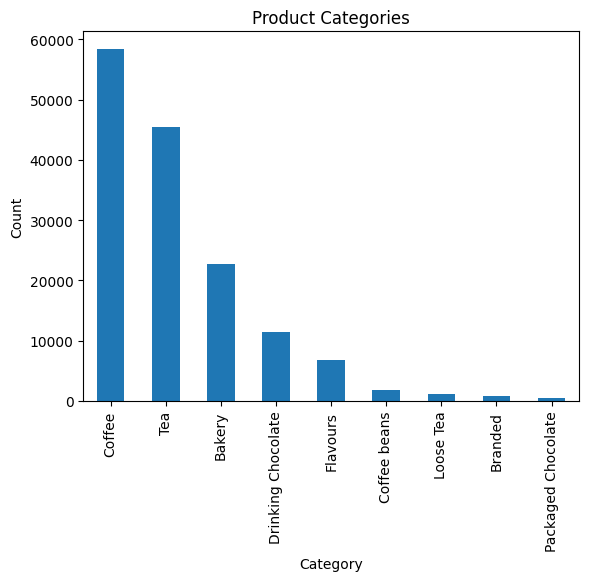

In [15]:
# Count product categories
df['product_category'].value_counts().plot(kind='bar')

# Add title and labels
plt.title('Product Categories')
plt.xlabel('Category')
plt.ylabel('Count')
plt.show()

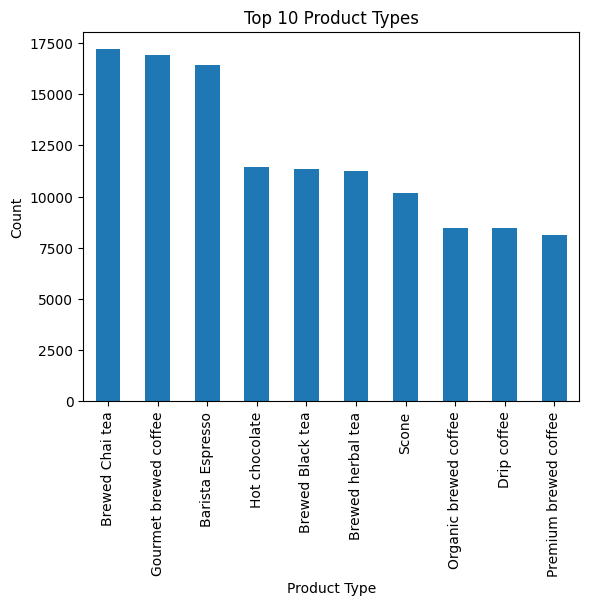

In [16]:
# Count product types
df['product_type'].value_counts().head(10).plot(kind='bar')

# Add title and labels
plt.title('Top 10 Product Types')
plt.xlabel('Product Type')
plt.ylabel('Count')
plt.show()

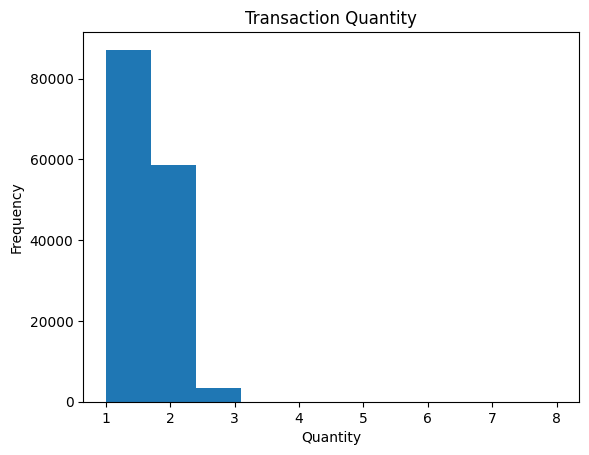

In [17]:
# Show transaction quantity distribution
plt.hist(df['transaction_qty'])

# Add title and labels
plt.title('Transaction Quantity')
plt.xlabel('Quantity')
plt.ylabel('Frequency')
plt.show()

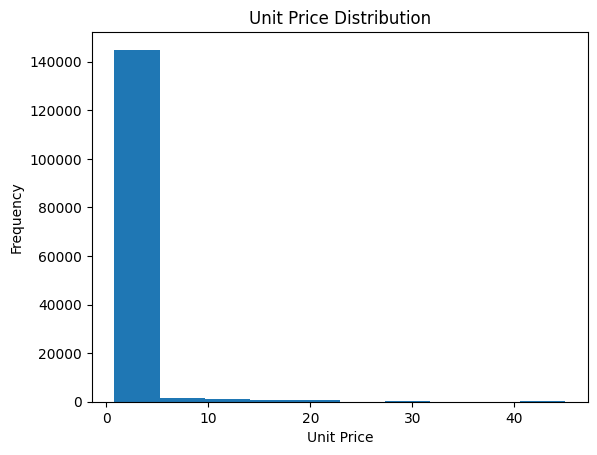

In [18]:
# Show unit price distribution
plt.hist(df['unit_price'])

# Add title and labels
plt.title('Unit Price Distribution')
plt.xlabel('Unit Price')
plt.ylabel('Frequency')
plt.show()

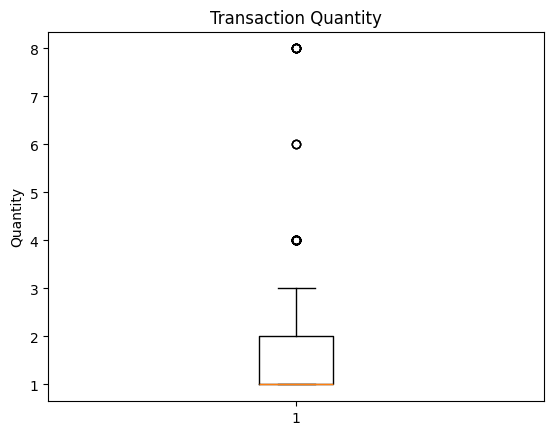

In [19]:
# Create a box plot
plt.boxplot(df['transaction_qty'])

# Add title
plt.title('Transaction Quantity')
plt.ylabel('Quantity')
plt.show()

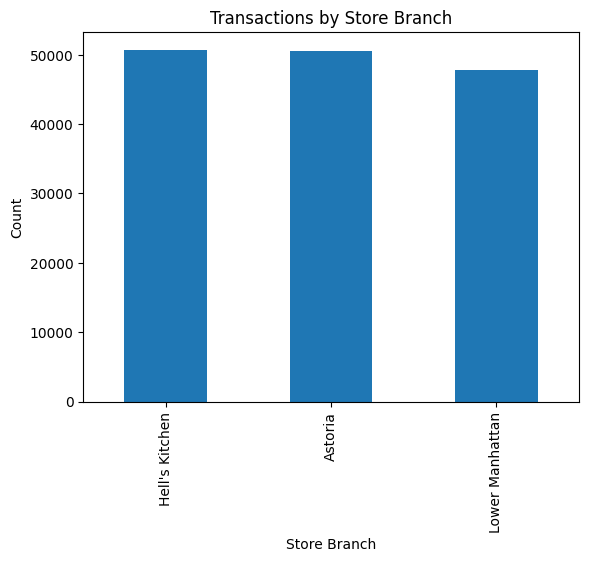

In [20]:
# Count transactions by store location
df['store_location'].value_counts().plot(kind='bar')

# Add title and labels
plt.title('Transactions by Store Branch')
plt.xlabel('Store Branch')
plt.ylabel('Count')
plt.show()

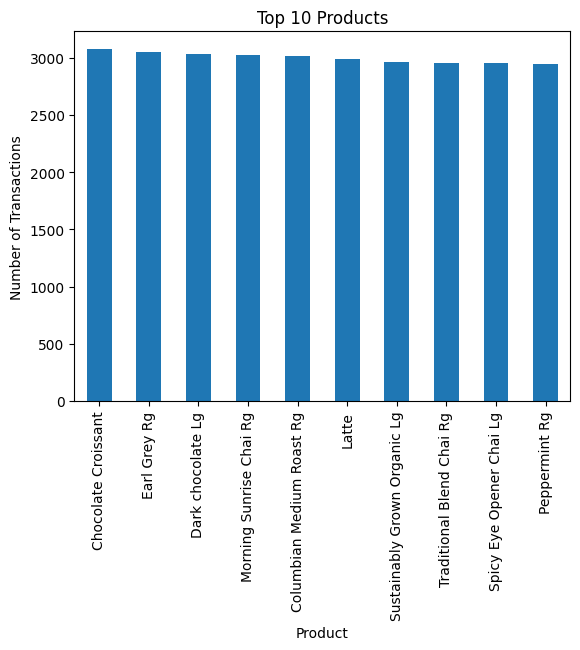

In [21]:
# Count product details
df['product_detail'].value_counts().head(10).plot(kind='bar')

# Add title and labels
plt.title('Top 10 Products')
plt.xlabel('Product')
plt.ylabel('Number of Transactions')
plt.show()

#Bivariate Analysis

**Unit Price vs Transaction Quantity**

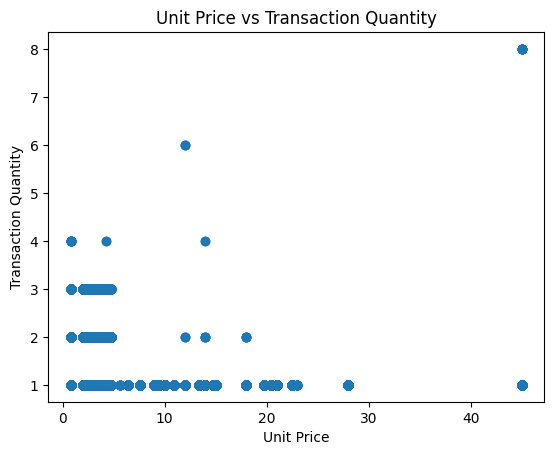

In [22]:
# Compare unit price and quantity
plt.scatter(df['unit_price'], df['transaction_qty'])

plt.title('Unit Price vs Transaction Quantity')
plt.xlabel('Unit Price')
plt.ylabel('Transaction Quantity')
plt.show()

**Product Category vs Unit Price**

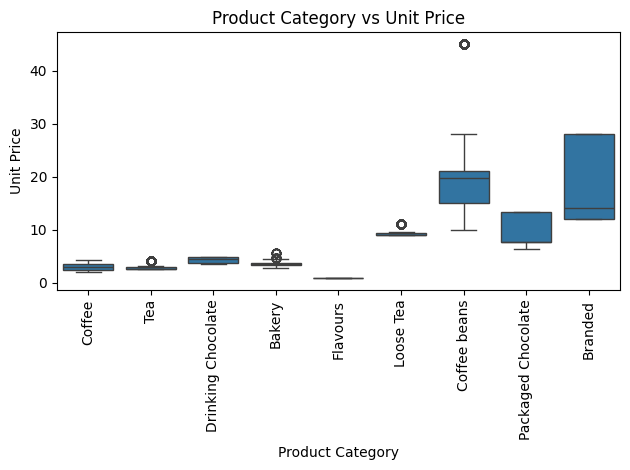

In [23]:
# Compare product category and unit price
sns.boxplot(x='product_category', y='unit_price', data=df)

plt.title('Product Category vs Unit Price')
plt.xlabel('Product Category')
plt.ylabel('Unit Price')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Store Location vs Transaction Quantity**

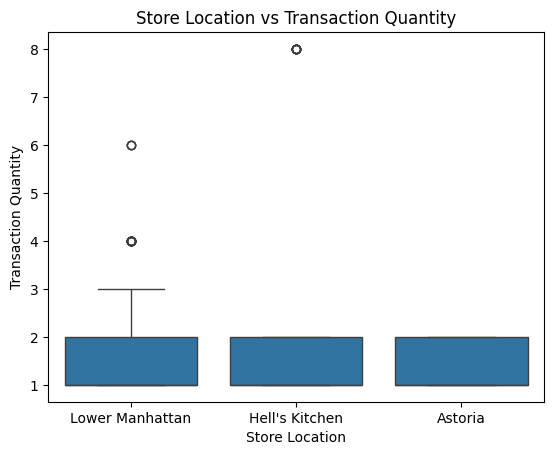

In [24]:
# Compare store location and transaction quantity
sns.boxplot(x='store_location', y='transaction_qty', data=df)

plt.title('Store Location vs Transaction Quantity')
plt.xlabel('Store Location')
plt.ylabel('Transaction Quantity')
plt.show()

**Correlation Heatmap**

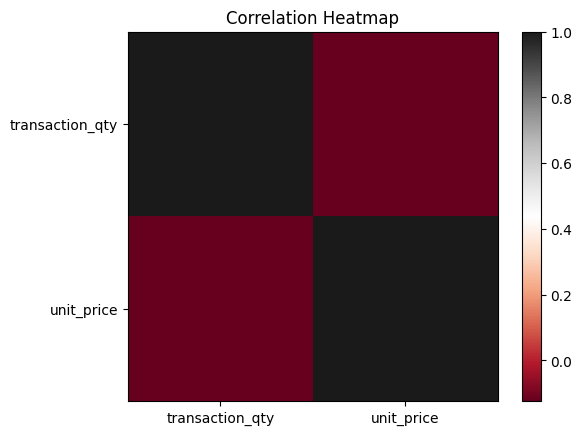

In [25]:
# Calculate correlation
corr = df[['transaction_qty', 'unit_price']].corr()

# Create heatmap
plt.imshow(corr, cmap='RdGy')
plt.colorbar()

# Add column names
plt.xticks([0, 1], corr.columns)
plt.yticks([0, 1], corr.columns)

# Add title
plt.title('Correlation Heatmap')
plt.show()

In [26]:
# Count transactions by product category
df['product_category'].value_counts()

,count
product_category,
Coffee,58416
Tea,45449
Bakery,22796
Drinking Chocolate,11468
Flavours,6790
Coffee beans,1753
Loose Tea,1210
Branded,747
Packaged Chocolate,487


**Product Category vs Transaction Quantity.**

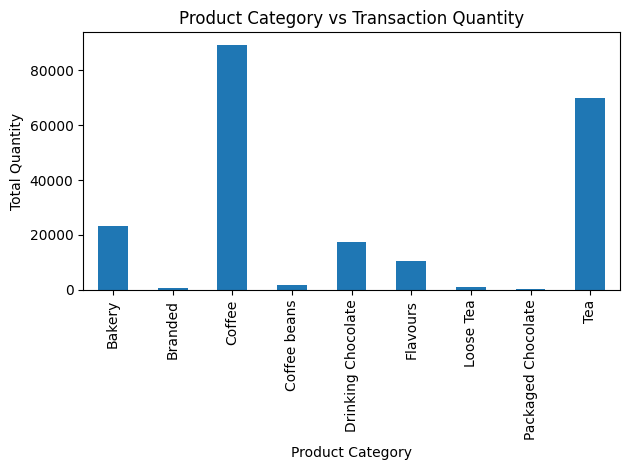

In [27]:
# Compare product category and transaction quantity
df.groupby('product_category')['transaction_qty'].sum().plot(kind='bar')

plt.title('Product Category vs Transaction Quantity')
plt.xlabel('Product Category')
plt.ylabel('Total Quantity')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Product Type vs Transaction Quantity.**

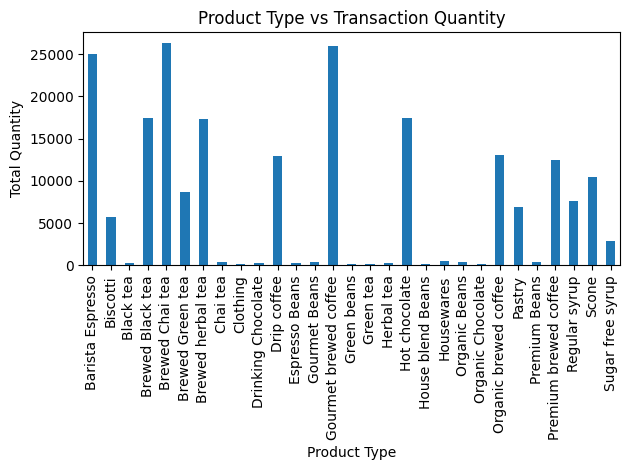

In [28]:
# Compare product type and transaction quantity
df.groupby('product_type')['transaction_qty'].sum().plot(kind='bar')

plt.title('Product Type vs Transaction Quantity')
plt.xlabel('Product Type')
plt.ylabel('Total Quantity')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

#Group Comparison

**Store Location vs Total Sales.**

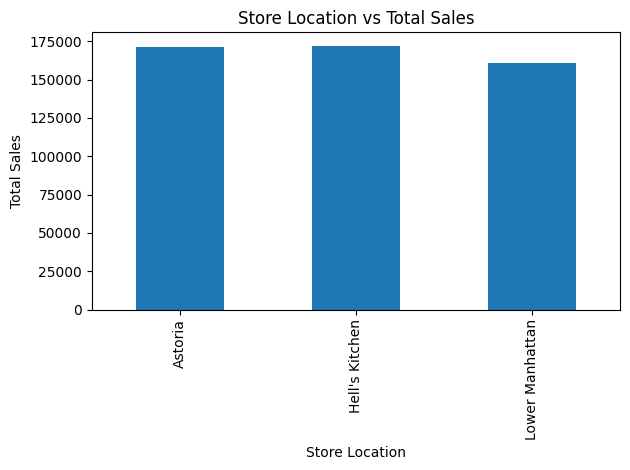

In [29]:
# Store Location vs Total Sales
df.groupby('store_location')['unit_price'].sum().plot(kind='bar')

plt.title('Store Location vs Total Sales')
plt.xlabel('Store Location')
plt.ylabel('Total Sales')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Store Location vs Total Sales.**

In [30]:
# Calculate total sales
df['sales'] = df['transaction_qty'] * df['unit_price']

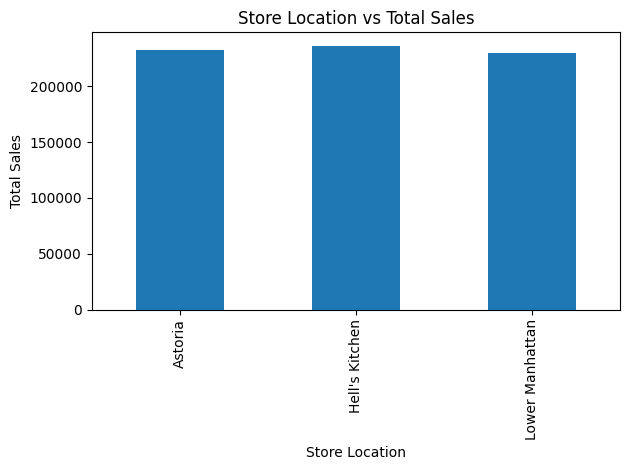

In [31]:
# Store Location vs Total Sales
df.groupby('store_location')['sales'].sum().plot(kind='bar')

plt.title('Store Location vs Total Sales')
plt.xlabel('Store Location')
plt.ylabel('Total Sales')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Month vs Total Sales.**

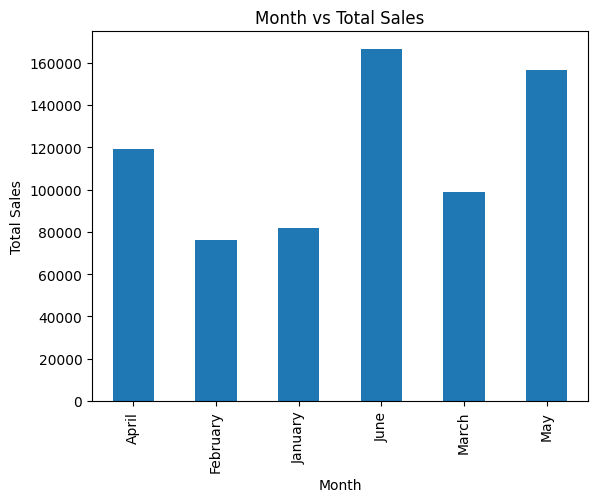

In [32]:
# Month vs Total Sales
df.groupby(df['transaction_date'].dt.month_name())['sales'].sum().plot(kind='bar')

plt.title('Month vs Total Sales')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.show()

**Product Category vs Total Revenue.**

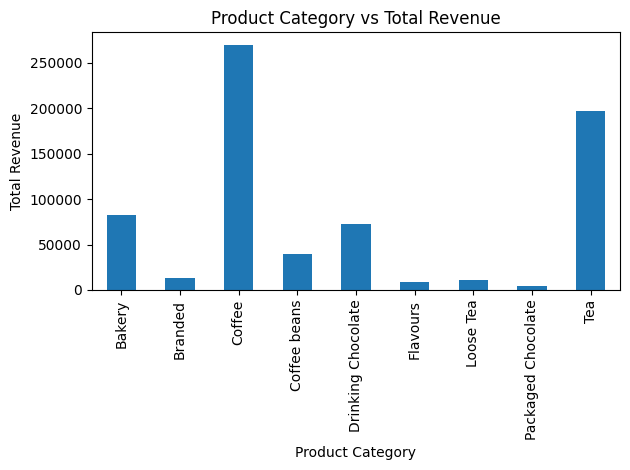

In [33]:
# Product Category vs Total Revenue
df.groupby('product_category')['sales'].sum().plot(kind='bar')

plt.title('Product Category vs Total Revenue')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

#Answers to Analysis Questions

**Q1. Which italicized text product category has the highest number of transactions?**

Answer: Coffee — 58,416 transactions.

**Q2. Which product type is sold the most?**




In [34]:
# Find the most sold product type
df['product_type'].value_counts().head(1)

,count
product_type,
Brewed Chai tea,17183


Answer: Brewed Chai tea — 17,183 transactions

**Q3. What is the most common transaction quantity?**



In [35]:
# Find the most common transaction quantity
df['transaction_qty'].value_counts().head(1)

,count
transaction_qty,
1,87159


Answer: 1 item — 87,159 transactions.

**Q4. How do transaction quantities vary across product categories?**

In [36]:
# Find total quantity for each product category
df.groupby('product_category')['transaction_qty'].sum()

,transaction_qty
product_category,
Bakery,23214
Branded,776
Coffee,89250
Coffee beans,1828
Drinking Chocolate,17457
Flavours,10511
Loose Tea,1210
Packaged Chocolate,487
Tea,69737


Answer: Coffee has the highest quantity sold (89,250), while Branded products have the lowest (776).

**Q5. Is there a relationship between unit price and transaction quantity?**

In [37]:
# Find the relationship between price and quantity
df['unit_price'].corr(df['transaction_qty'])

np.float64(-0.12354566015198777)

Answer: There is a very weak negative relationship between price and quantity. As price increases, quantity tends to decrease slightly.

**Q6. Which store location has the highest total sales?**

In [38]:
# Find total sales for each store
df.groupby('store_location')['sales'].sum().sort_values(ascending=False)

,sales
store_location,
Hell's Kitchen,236511.17
Astoria,232243.91
Lower Manhattan,230057.25


Answer: Hell's Kitchen has the highest total sales of 236,511.17.

**Q7. Which month has the highest total sales?**

In [39]:
# Find total sales for each month
df.groupby(df['transaction_date'].dt.month_name())['sales'].sum().sort_values(ascending=False)

,sales
transaction_date,
June,166485.88
May,156727.76
April,118941.08
March,98834.68
January,81677.74
February,76145.19


Answer: June has the highest total sales of 166,485.88.

**Q8. Which product category generates the highest revenue?**

In [40]:
# Find total revenue for each product category
df.groupby('product_category')['sales'].sum().sort_values(ascending=False)

,sales
product_category,
Coffee,269952.45
Tea,196405.95
Bakery,82315.64
Drinking Chocolate,72416.00
Coffee beans,40085.25
Branded,13607.00
Loose Tea,11213.60
Flavours,8408.80
Packaged Chocolate,4407.64


Answer: Coffee generates the highest revenue of 269,952.45.

**Conclusion**
- Coffee is the most popular product category and generates the highest revenue.
- June has the highest total sales.
- Hell's Kitchen store has the highest total sales.
- The shop can increase sales by promoting less popular product categories.

#Streamlit Dashboard Development

In [41]:
%%writefile app.py

# Import libraries
import streamlit as st
import pandas as pd
import plotly.express as px

Writing app.py


In [42]:
%%writefile -a app.py

# Load the dataset
df = pd.read_csv('coffee_shop_sales.csv')

# Calculate total sales
df['sales'] = df['transaction_qty'] * df['unit_price']

Appending to app.py


In [43]:
%%writefile -a app.py

# Add dashboard title
st.title('Coffee Shop Sales Dashboard')

# Add dashboard description
st.write('Explore coffee shop sales through charts and filters.')

Appending to app.py


In [44]:
%%writefile -a app.py

# Add store filter
store = st.sidebar.selectbox(
    'Select Store',
    df['store_location'].unique()
)

# Filter data by store
df = df[df['store_location'] == store]

Appending to app.py


In [45]:
%%writefile -a app.py

# Add product category filter
category = st.sidebar.selectbox(
    'Select Product Category',
    df['product_category'].unique()
)

# Filter data by category
df = df[df['product_category'] == category]

Appending to app.py


In [46]:
# Display the dashboard code
!cat app.py


# Import libraries
import streamlit as st
import pandas as pd
import plotly.express as px

# Load the dataset
df = pd.read_csv('coffee_shop_sales.csv')

# Calculate total sales
df['sales'] = df['transaction_qty'] * df['unit_price']

# Add dashboard title
st.title('Coffee Shop Sales Dashboard')

# Add dashboard description
st.write('Explore coffee shop sales through charts and filters.')

# Add store filter
store = st.sidebar.selectbox(
    'Select Store',
    df['store_location'].unique()
)

# Filter data by store
df = df[df['store_location'] == store]

# Add product category filter
category = st.sidebar.selectbox(
    'Select Product Category',
    df['product_category'].unique()
)

# Filter data by category
df = df[df['product_category'] == category]


In [47]:

# Read the Excel dataset
df = pd.read_excel('/content/Coffee Shop Sales.xlsx')

# Save it as a CSV file
df.to_csv('coffee_shop_sales.csv', index=False)

In [48]:
# Check the CSV file
import os
print(os.listdir())

['.config', 'app.py', 'coffee_shop_sales.csv', 'Coffee Shop Sales.xlsx', 'sample_data']


In [49]:
%%writefile -a app.py

# Show key metrics
col1, col2, col3, col4 = st.columns(4)

col1.metric('Total Sales', round(df['sales'].sum(), 2))
col2.metric('Total Transactions', len(df))
col3.metric('Total Quantity', df['transaction_qty'].sum())
col4.metric('Average Price', round(df['unit_price'].mean(), 2))

Appending to app.py


In [50]:
%%writefile -a app.py

# Sales by product category
sales_category = df.groupby('product_category')['sales'].sum().reset_index()

fig = px.bar(sales_category, x='product_category', y='sales',
             title='Sales by Product Category')

st.plotly_chart(fig)

Appending to app.py


In [51]:
%%writefile -a app.py

# Sales by store location
sales_store = df.groupby('store_location')['sales'].sum().reset_index()

fig = px.bar(sales_store, x='store_location', y='sales',
             title='Sales by Store Location')

st.plotly_chart(fig)

Appending to app.py


In [52]:
%%writefile -a app.py

# Monthly sales
df['month'] = pd.to_datetime(df['transaction_date']).dt.month_name()
monthly_sales = df.groupby('month')['sales'].sum().reset_index()

fig = px.bar(monthly_sales, x='month', y='sales',
             title='Monthly Sales')

st.plotly_chart(fig)

Appending to app.py


In [53]:
%%writefile -a app.py

# Top 10 products
top_products = df['product_detail'].value_counts().head(10).reset_index()
top_products.columns = ['product_detail', 'count']

fig = px.bar(top_products, x='product_detail', y='count',
             title='Top 10 Products')

st.plotly_chart(fig)

Appending to app.py


In [54]:
%%writefile -a app.py

# Sales by product type
sales_type = df.groupby('product_type')['sales'].sum().reset_index()

fig = px.bar(sales_type, x='product_type', y='sales',
             title='Sales by Product Type')

st.plotly_chart(fig)

Appending to app.py


In [55]:
%%writefile -a app.py

# Show raw data
if st.checkbox('Show Raw Data'):
    st.dataframe(df)

Appending to app.py


In [56]:
%%writefile -a app.py

# Show key findings
st.subheader('Key Findings')
st.write('Coffee is the most popular product category.')
st.write('June has the highest total sales.')
st.write("Hell's Kitchen has the highest total sales among store locations.")

Appending to app.py
